# Error analysis: where the four final models fail on clean test

Run after `test_evaluation.ipynb`, with every model and decision frozen: nothing here feeds back into a choice. It
asks two questions:

1. **Do the models fail on the same images?** If the compressed models miss the same tumours as the large model,
   those images are hard in themselves; if not, the errors come from the individual models.
2. **What do the failures look like?** Every missed tumour is shown as stored and as the model sees it (cropped to
   the head, grayscale, 128 px), next to correctly detected tumours of the same classes for comparison.

Predictions use the tumour decision rule from c10 (argmax, except a cutoff on P(tumour) for the 1.4 kB model), as
in the test evaluation.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
sys.path.insert(0, "..")
from lib.train import Config, build_model, prepare_data, predict, DEVICE, RESULTS, CKPT
from lib.data import ARTIFACTS, CLASSES, NO_TUMOR, SEED, DATA_ROOT, load_split, GPUSplit
from lib.evaluation import tumor_score

PICKS = json.loads((ARTIFACTS / "compress_final.json").read_text())        # the compressed models chosen in d6
RUNS = {"large": "c9/final_s1738", **{f"{p['stored kB']:.1f} kB": f"{p['record']}_s1738" for p in PICKS.values()}}
RUNS = dict(sorted(RUNS.items(), key=lambda kv: -float(kv[0].split()[0]) if kv[0] != "large" else -1e9))
CUTOFF = json.loads((ARTIFACTS / "threshold.json").read_text())["decisions"]
NAMES = list(RUNS)

def decide(prob, cutoff):
    if cutoff is None:
        return prob.argmax(1)
    p = prob.copy(); p[:, NO_TUMOR] = -1
    return np.where(tumor_score(prob) >= cutoff, p.argmax(1), NO_TUMOR)

prob, pred = {}, {}
for name, run in RUNS.items():
    rec = json.loads((RESULTS / f"{run}.json").read_text())
    cfg = Config(**{k: tuple(v) if isinstance(v, list) else v for k, v in rec["config"].items()})
    train, _ = prepare_data(cfg)
    net = build_model(cfg, train.X.shape[1])
    net.load_state_dict(torch.load(CKPT / f"{run}.pt", map_location="cpu"))
    test = load_split("test", cfg.mode, cfg.resize, cfg.size, clean=True)
    te = GPUSplit(test, DEVICE, train.mean, train.std, cfg.normalize == "per_image")
    prob[name] = predict(net.to(DEVICE), te)
    pred[name] = decide(prob[name], CUTOFF[name])
y, paths, X = te.y.cpu().numpy(), te.paths, test["X"]          # identical for every model (same input settings)
tum = y != NO_TUMOR
print(f"clean test: {len(y)} images, {tum.sum()} tumours, {(~tum).sum()} no_tumor; models: {NAMES}")

clean test: 833 images, 728 tumours, 105 no_tumor; models: ['large', '18.8 kB', '9.3 kB', '1.4 kB']


## 1. Do the models fail on the same images?

Three kinds of error, per model: a **missed tumour** (tumour predicted as no_tumor), a **false alarm** (no_tumor
predicted as a tumour) and a **wrong tumour type** (right that there is a tumour, wrong class). For each pair of
models the table counts the images both get wrong. As a reference, it also gives the count expected if the two
models erred **independently** of each other: n_a · n_b / N, with N the number of images the error can occur on.
Many more shared errors than that means the errors sit in the images, not in the models.

In [2]:
KINDS = {"missed tumour": (tum, lambda p: p == NO_TUMOR),
         "false alarm": (~tum, lambda p: p != NO_TUMOR),
         "wrong tumour type": (tum, lambda p: (p != NO_TUMOR) & (p != y)),
         "any error": (np.ones_like(tum), lambda p: p != y)}
ERR = {k: {n: np.flatnonzero(elig & f(pred[n])) for n in NAMES} for k, (elig, f) in KINDS.items()}

for kind, (elig, _) in KINDS.items():
    N, sets = int(elig.sum()), {n: set(ERR[kind][n]) for n in NAMES}
    shared = pd.DataFrame([[len(sets[a] & sets[b]) for b in NAMES] for a in NAMES], index=NAMES, columns=NAMES)
    expect = pd.DataFrame([[len(sets[a]) * len(sets[b]) / N for b in NAMES] for a in NAMES], index=NAMES, columns=NAMES)
    table = shared.astype(str) + " (" + expect.round(1).astype(str) + ")"
    for n in NAMES:
        table.loc[n, n] = str(len(sets[n]))
    print(f"{kind} (of {N} images): diagonal = errors per model; off-diagonal = shared (expected if independent)")
    display(table)

missed tumour (of 728 images): diagonal = errors per model; off-diagonal = shared (expected if independent)


,large,18.8 kB,9.3 kB,1.4 kB
large,9,4 (0.1),3 (0.1),6 (0.1)
18.8 kB,4 (0.1),8,3 (0.1),3 (0.1)
9.3 kB,3 (0.1),3 (0.1),8,3 (0.1)
1.4 kB,6 (0.1),3 (0.1),3 (0.1),8


false alarm (of 105 images): diagonal = errors per model; off-diagonal = shared (expected if independent)


,large,18.8 kB,9.3 kB,1.4 kB
large,6,4 (0.5),4 (0.5),5 (1.9)
18.8 kB,4 (0.5),8,5 (0.6),8 (2.5)
9.3 kB,4 (0.5),5 (0.6),8,7 (2.5)
1.4 kB,5 (1.9),8 (2.5),7 (2.5),33


wrong tumour type (of 728 images): diagonal = errors per model; off-diagonal = shared (expected if independent)


,large,18.8 kB,9.3 kB,1.4 kB
large,19,9 (0.6),9 (1.0),12 (2.6)
18.8 kB,9 (0.6),23,12 (1.2),13 (3.2)
9.3 kB,9 (1.0),12 (1.2),37,27 (5.1)
1.4 kB,12 (2.6),13 (3.2),27 (5.1),100


any error (of 833 images): diagonal = errors per model; off-diagonal = shared (expected if independent)


,large,18.8 kB,9.3 kB,1.4 kB
large,34,17 (1.6),18 (2.2),25 (5.8)
18.8 kB,17 (1.6),39,24 (2.5),27 (6.6)
9.3 kB,18 (2.2),24 (2.5),53,38 (9.0)
1.4 kB,25 (5.8),27 (6.6),38 (9.0),141


number of models that get it wrong,1,2,3,4
missed tumour,11,4,2,2
false alarm,24,6,1,4
wrong tumour type,90,19,9,6
any error,118,26,15,13


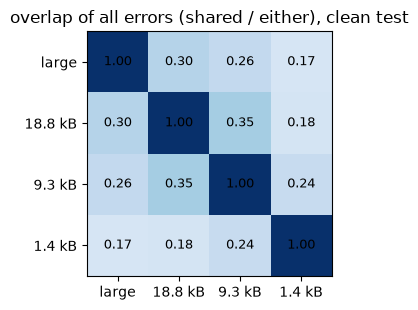

In [3]:
def n_wrong(kind):                                             # per image: how many models make this error
    return sum(np.isin(np.arange(len(y)), ERR[kind][n]) for n in NAMES)
counts = pd.DataFrame({kind: np.bincount(n_wrong(kind), minlength=len(NAMES) + 1)[1:] for kind in KINDS},
                      index=range(1, len(NAMES) + 1))
counts.index.name = "number of models that get it wrong"
display(counts.T)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.imshow([[len(set(ERR["any error"][a]) & set(ERR["any error"][b])) / len(set(ERR["any error"][a]) | set(ERR["any error"][b]))
            for b in NAMES] for a in NAMES], vmin=0, vmax=1, cmap="Blues")
for i, a in enumerate(NAMES):
    for j, b in enumerate(NAMES):
        sa, sb = set(ERR["any error"][a]), set(ERR["any error"][b])
        ax.text(j, i, f"{len(sa & sb) / len(sa | sb):.2f}", ha="center", va="center", fontsize=9)
ax.set(xticks=range(len(NAMES)), xticklabels=NAMES, yticks=range(len(NAMES)), yticklabels=NAMES,
       title="overlap of all errors (shared / either), clean test")
plt.tight_layout(); plt.show()

* **The models share errors far more often than chance.** The large and 18.8 kB models both miss 4 tumours where
  0.1 would be expected if they erred independently, and share 17 errors of any kind where 1.6 would be expected.
  Part of the difficulty therefore lies in the images themselves.
* **Still, most errors belong to one model.** Of the 19 tumours missed by at least one model, 11 are missed by
  only one and 2 by all four; of the 172 images that any model gets wrong, 118 are wrong for one model only. The
  overlap of two models' errors (shared / either) is 0.17 to 0.35.
* The two larger compressed models overlap most with each other (0.35), the 1.4 kB model least with the others.
  Because the errors differ, combining the models (for example averaging their probabilities) could remove some
  of them; this was not tested.

## 2. The missed tumours

In [4]:
missed = sorted(set(np.concatenate([ERR["missed tumour"][n] for n in NAMES])),
                key=lambda i: (-sum(pred[n][i] == NO_TUMOR for n in NAMES), y[i], paths[i]))
def stored_info(i):
    with Image.open(DATA_ROOT / paths[i]) as im:
        a = np.asarray(im.convert("RGB")).astype(int)
        return {"stored size": f"{im.size[0]}x{im.size[1]}", "format": im.format,
                "colour": "yes" if np.abs(a - a.mean(2, keepdims=True)).max() > 10 else "no"}
M = pd.DataFrame([{"#": k, "file": paths[i].split("/")[-1], "true class": CLASSES[y[i]],
                   "missed by": ", ".join(n for n in NAMES if pred[n][i] == NO_TUMOR),
                   **{f"P(tumour) {n}": round(float(tumor_score(prob[n])[i]), 3) for n in NAMES}, **stored_info(i)}
                  for k, i in enumerate(missed, 1)]).set_index("#")
display(M)

,file,true class,missed by,P(tumour) large,P(tumour) 18.8 kB,P(tumour) 9.3 kB,P(tumour) 1.4 kB,stored size,format,colour
#,,,,,,,,,,
1,glioma_test_00322.jpg,glioma,"large, 18.8 kB, 9.3 kB, 1.4 kB",0.472,0.472,0.177,0.057,224x224,JPEG,no
2,meningioma_test_00010.jpg,meningioma,"large, 18.8 kB, 9.3 kB, 1.4 kB",0.073,0.233,0.135,0.219,230x241,JPEG,no
3,glioma_test_00289.jpg,glioma,"large, 18.8 kB, 9.3 kB",0.561,0.380,0.529,0.337,337x412,JPEG,no
4,meningioma_test_00148.jpg,meningioma,"large, 18.8 kB, 1.4 kB",0.124,0.384,0.549,0.087,224x224,JPEG,no
5,glioma_test_00172.jpg,glioma,"9.3 kB, 1.4 kB",0.973,0.870,0.367,0.168,175x167,JPEG,no
6,glioma_test_00246.jpg,glioma,"large, 1.4 kB",0.522,0.982,0.960,0.260,509x537,JPEG,no
7,glioma_test_00306.jpg,glioma,"large, 1.4 kB",0.535,0.681,0.620,0.053,224x224,JPEG,no
8,meningioma_test_00008.jpg,meningioma,"large, 1.4 kB",0.503,0.855,0.919,0.126,455x500,JPEG,no
9,glioma_test_00012.jpg,glioma,1.4 kB,0.851,0.958,0.907,0.119,224x224,JPEG,no


Each missed tumour, as stored (top) and as the models see it (bottom: head crop, grayscale, 128 px). The number
matches the table above.

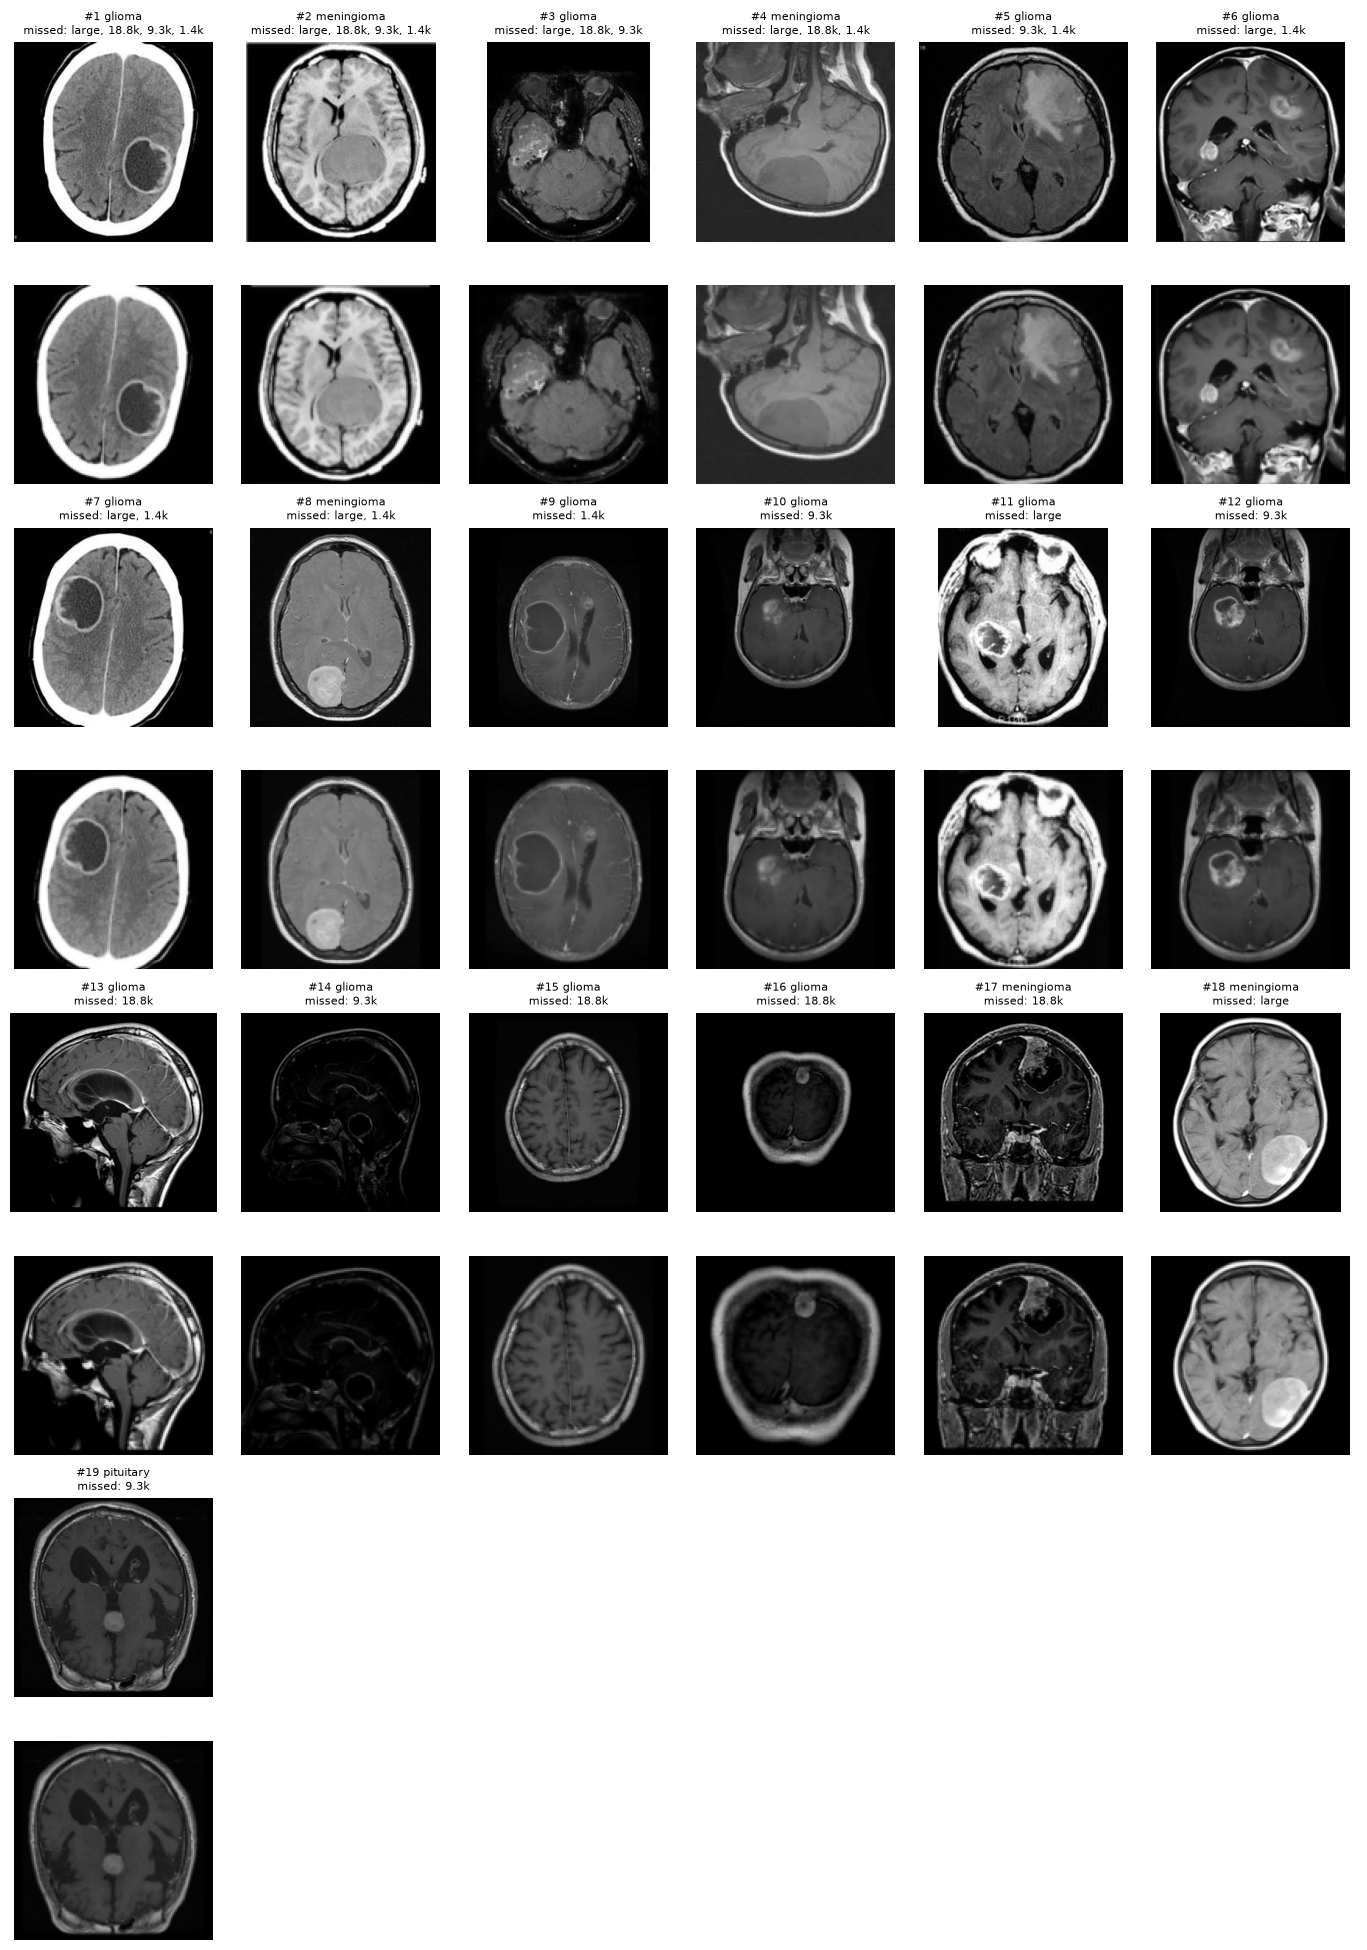

In [5]:
def show(idx, labels, ncol=6):
    nrow = -(-len(idx) // ncol)
    fig, axes = plt.subplots(2 * nrow, ncol, figsize=(2.3 * ncol, 4.9 * nrow))
    for a in axes.flat:
        a.axis("off")
    for k, (i, lab) in enumerate(zip(idx, labels)):
        r, c = 2 * (k // ncol), k % ncol
        with Image.open(DATA_ROOT / paths[i]) as im:
            axes[r, c].imshow(im.convert("RGB"))
        axes[r, c].set_title(lab, fontsize=8)
        axes[r + 1, c].imshow(X[i, 0], cmap="gray", vmin=0, vmax=255)
    plt.tight_layout(); plt.show()

short = {n: n.replace(" kB", "k") for n in NAMES}
show(missed, [f"#{k} {CLASSES[y[i]]}\nmissed: {', '.join(short[n] for n in NAMES if pred[n][i] == NO_TUMOR)}"
              for k, i in enumerate(missed, 1)])

For comparison: tumours that **every** model detects, drawn at random (seed 1738) with the same number per class
as the missed tumours.

,file,true class,stored size,format,colour
0,glioma_test_00259.jpg,glioma,512x512,JPEG,no
1,glioma_test_00010.jpg,glioma,512x512,JPEG,no
2,glioma_test_00256.jpg,glioma,512x512,JPEG,no
3,glioma_test_00312.jpg,glioma,224x224,JPEG,no
4,glioma_test_00085.jpg,glioma,512x512,JPEG,no
5,glioma_test_00258.jpg,glioma,224x224,JPEG,no
6,glioma_test_00284.jpg,glioma,512x512,JPEG,no
7,glioma_test_00076.jpg,glioma,512x512,JPEG,no
8,glioma_test_00017.jpg,glioma,224x224,JPEG,no
9,glioma_test_00311.jpg,glioma,224x224,JPEG,no


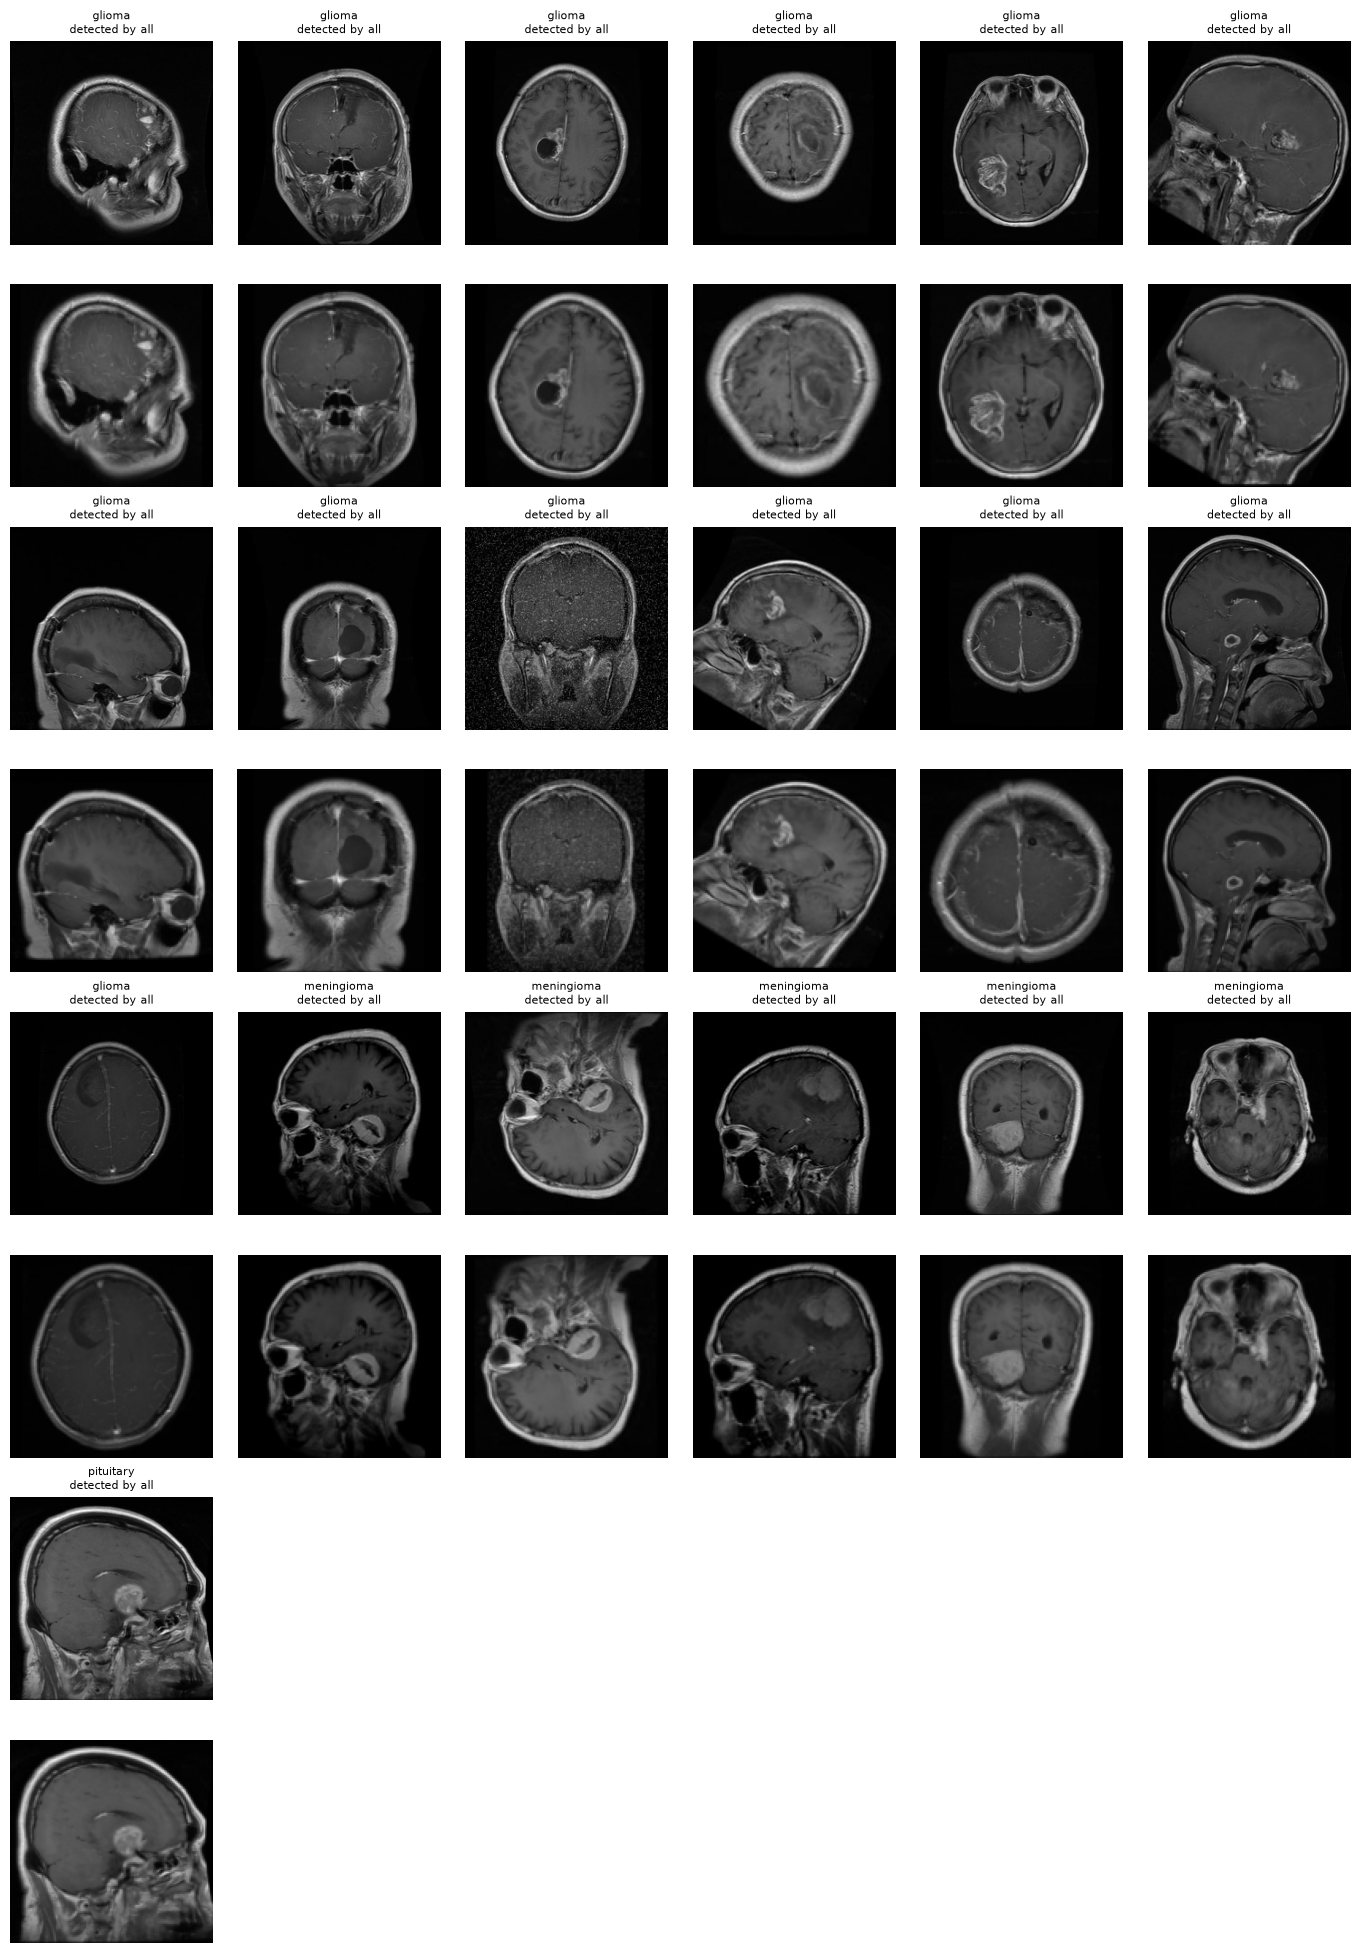

In [6]:
rng = np.random.default_rng(SEED)
caught = np.flatnonzero(tum & np.all([pred[n] != NO_TUMOR for n in NAMES], axis=0))
ctrl = np.concatenate([rng.choice(caught[y[caught] == c], n, replace=False)
                       for c, n in zip(*np.unique(y[missed], return_counts=True))])
display(pd.DataFrame([{"file": paths[i].split("/")[-1], "true class": CLASSES[y[i]], **stored_info(i)} for i in ctrl]))
show(ctrl, [f"{CLASSES[y[i]]}\ndetected by all" for i in ctrl])

**What the missed tumours have in common** (judged by eye, not measured):

* **They come from a mix of scan types and equipment.** #1 and #7 look like CT rather than MRI, #5 and #18 like
  FLAIR or T2-weighted MRI, #2 like T1 without contrast agent. The correctly detected tumours are almost all of
  one kind (T1-weighted with contrast agent).
* **Their contrast varies widely** compared with the rest of the data set: some are very dark (#14), some very
  bright (#11), some flat and grey (#1, #7).
* **Framing and zoom are irregular.** Some are cut very close or show an unusual part of the head (#3, #4: skull
  base and cerebellum), others show a small head in a large frame (#16), and some are side views (#13, #14).
* **The correctly detected tumours look alike**: very similar contrast, layout and position of the head in the
  frame.

## 3. The false alarms of the three larger models

No-tumour scans that the large, 18.8 kB or 9.3 kB model calls a tumour. (The 1.4 kB model's false alarms are
not shown: its cutoff trades specificity for sensitivity by design, see c10.)

,file,flagged by,predicted (large),predicted (18.8 kB),predicted (9.3 kB),stored size,format,colour
#,,,,,,,,
1,no_tumor_test_00006.jpg,"large, 18.8 kB, 9.3 kB",pituitary,pituitary,pituitary,235x216,JPEG,no
2,no_tumor_test_00033.jpg,"large, 18.8 kB, 9.3 kB",glioma,glioma,glioma,504x488,JPEG,no
3,no_tumor_test_00094.jpg,"large, 18.8 kB, 9.3 kB",pituitary,pituitary,pituitary,236x201,JPEG,no
4,no_tumor_test_00108.jpg,"large, 18.8 kB, 9.3 kB",glioma,meningioma,glioma,442x442,JPEG,no
5,no_tumor_test_00032.jpg,"18.8 kB, 9.3 kB",no_tumor,glioma,meningioma,224x224,JPEG,no
6,no_tumor_test_00005.jpg,9.3 kB,no_tumor,no_tumor,pituitary,224x224,JPEG,no
7,no_tumor_test_00007.jpg,18.8 kB,no_tumor,glioma,no_tumor,224x224,JPEG,no
8,no_tumor_test_00024.jpg,large,meningioma,no_tumor,no_tumor,236x236,JPEG,no
9,no_tumor_test_00026.jpg,9.3 kB,no_tumor,no_tumor,glioma,224x224,JPEG,no


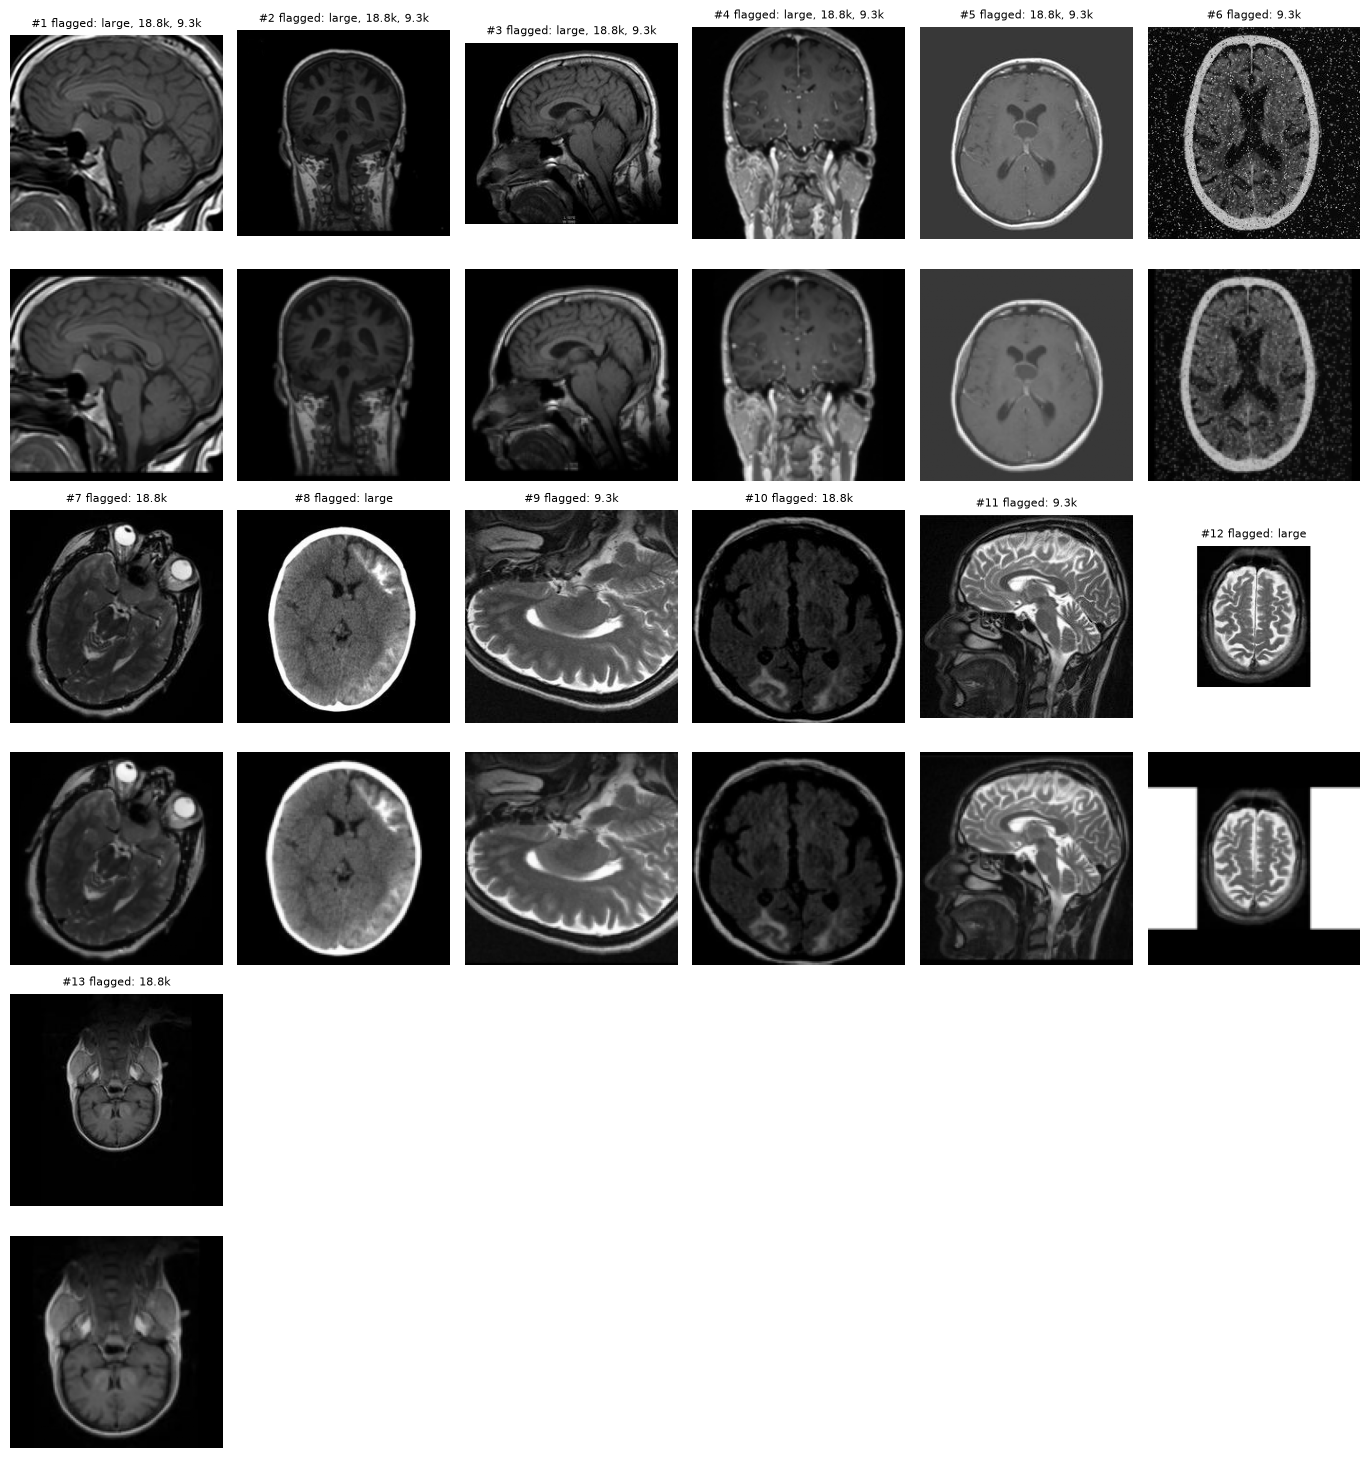

In [7]:
big = NAMES[:3]
fa = sorted(set(np.concatenate([ERR["false alarm"][n] for n in big])),
            key=lambda i: (-sum(pred[n][i] != NO_TUMOR for n in big), paths[i]))
display(pd.DataFrame([{"#": k, "file": paths[i].split("/")[-1],
                       "flagged by": ", ".join(n for n in big if pred[n][i] != NO_TUMOR),
                       **{f"predicted ({n})": CLASSES[pred[n][i]] for n in big}, **stored_info(i)}
                      for k, i in enumerate(fa, 1)]).set_index("#"))
show(fa, [f"#{k} flagged: {', '.join(short[n] for n in big if pred[n][i] != NO_TUMOR)}" for k, i in enumerate(fa, 1)])

**What the false alarms have in common** (judged by eye, not measured):

* **Contrast differs from the typical scan**: T2-weighted images with bright fluid (#7, #9, #11), a CT-like scan
  (#8), a grey instead of black background (#5), heavy noise (#6).
* **Cropping goes wrong or the head sits oddly in the frame.** #12 has white margins around the scan, so the head
  crop kept the whole image and the model sees white bars next to the head; #1 and #3 are cut off at the edge.
* **Irregular positioning**: tilted or low slices (#7, #9, #13) and side or front views (#1 to #4).

## Summary

Errors are spread across the models rather than concentrated on a few impossible images, but they are not
random either: **both kinds of error happen on images that look different from the bulk of the data set**, in scan
type, contrast, framing or borders. The correctly classified images are much more uniform. This points to a
model that has learnt the typical appearance of each class in this data set, and generalises poorly to scans
that depart from it.

It matches the shortcut risk found in c1: the tumour classes are almost all T1-weighted MRI with contrast agent,
while no_tumor mixes T2, FLAIR, non-contrast T1, CT and odd crops. A model can therefore partly learn "atypical
scan means no tumour". The errors look like exactly that: tumours on CT, FLAIR or T2 scans are called no_tumor,
and healthy scans that look like the typical tumour images are called tumours.

**Stronger augmentation** (more contrast, zoom and rotation variation) was tried in c8 and dropped, because it
did not raise the val score. Val has the same mix as training, dominated by typical scans, so that result does
not cover scans like the ones above. A model that has to handle images with this much variation would most likely
need it, and data from more sources.

Next steps this suggests (not tested): labelling the scan type per image, to measure how it is distributed over
the classes and over the errors; a head crop that handles bright borders; stronger augmentation evaluated on
atypical scans specifically.